In [23]:
import numpy as np
import pandas as pd

df = pd.read_csv("results/ik_collision/20261109_224232/all.csv")
ok = df.pivot_table(index=["obstacle", "scenario_id"], columns="method",
                    values="feasible", aggfunc="first").all(axis=1)
paired = df.set_index(["obstacle", "scenario_id"]).loc[ok[ok].index].reset_index()

t = paired.pivot_table(index=["obstacle", "scenario_id"], columns="method", values="solve_time_s")
speedup = t.rdiv(t["fcl"], axis=0)
print(speedup.groupby(level="obstacle").median())

method       coal_default  coal_nesterov  coal_polyak  fcl
obstacle                                                  
cube             1.845879       1.530134     1.841334  1.0
sphere_hull      1.822766       1.520526     1.784319  1.0


In [24]:
ok = df.pivot_table(index=["obstacle", "scenario_id"], columns="method",
                    values="feasible", aggfunc="first").all(axis=1)
paired = df.set_index(["obstacle", "scenario_id"]).loc[ok[ok].index].reset_index()
paired["solve_time_ms"] = 1e3 * paired["solve_time_s"]

cols = ["solve_time_ms", "cost", "max_violation", "min_distance", "gap_at_q0"]
table = paired.groupby(["obstacle", "method"])[cols].median()
table.insert(0, "n", paired.groupby(["obstacle", "method"]).size())
print(table.to_string(float_format=lambda x: f"{x:.4g}"))

                            n  solve_time_ms  cost  max_violation  min_distance  gap_at_q0
obstacle    method                                                                        
cube        coal_default   93          17.71 8.269          3e-08       0.03065      0.001
            coal_nesterov  93          22.67 8.377          3e-08       0.03065      0.001
            coal_polyak    93          18.51 8.377          3e-08       0.03065      0.001
            fcl            93          34.58 8.377          3e-08       0.03065      0.001
sphere_hull coal_default   97          18.43 9.416          3e-08       0.03065      0.001
            coal_nesterov  97          20.46   8.6          3e-08       0.03065      0.001
            coal_polyak    97          18.15 8.929          3e-08       0.03065      0.001
            fcl            97           30.8 9.352          3e-08       0.03066      0.001


Text(0, 0.5, 'IK solve time (ms)')

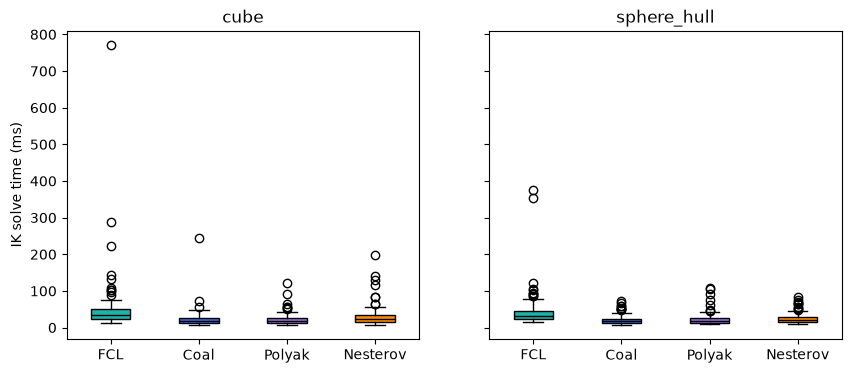

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


ok = df.pivot_table(index=["obstacle", "scenario_id"], columns="method",
                    values="feasible", aggfunc="first").all(axis=1)
df = df.set_index(["obstacle", "scenario_id"]).loc[ok[ok].index].reset_index()

methods = ["fcl", "coal_default", "coal_polyak", "coal_nesterov"]
labels = ["FCL", "Coal", "Polyak", "Nesterov"]
colors = ["lightseagreen", "royalblue", "mediumpurple", "darkorange"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, obstacle in zip(axes, ["cube", "sphere_hull"]):
    d = df[df.obstacle == obstacle]
    bp = ax.boxplot([1e3 * d[d.method == m].solve_time_s for m in methods],
                    patch_artist=True, showfliers=True, medianprops=dict(color="black"))
    for box, c in zip(bp["boxes"], colors):
        box.set_facecolor(c)
    ax.set_ylim(top=1e3 * d.solve_time_s.quantile(0.99))
    ax.set_xticks(range(1, 5), labels)
    ax.set_title(obstacle)
axes[0].set_ylabel("IK solve time (ms)")


In [26]:
fcl_time = table["solve_time_ms"].xs("fcl", level="method")
table["diff_vs_fcl_ms"] = table["solve_time_ms"] - fcl_time.reindex(table.index, level="obstacle")
print(table.to_string(float_format=lambda x: f"{x:.4g}"))

                            n  solve_time_ms  cost  max_violation  min_distance  gap_at_q0  diff_vs_fcl_ms
obstacle    method                                                                                        
cube        coal_default   93          17.71 8.269          3e-08       0.03065      0.001          -16.87
            coal_nesterov  93          22.67 8.377          3e-08       0.03065      0.001           -11.9
            coal_polyak    93          18.51 8.377          3e-08       0.03065      0.001          -16.07
            fcl            93          34.58 8.377          3e-08       0.03065      0.001               0
sphere_hull coal_default   97          18.43 9.416          3e-08       0.03065      0.001          -12.37
            coal_nesterov  97          20.46   8.6          3e-08       0.03065      0.001          -10.34
            coal_polyak    97          18.15 8.929          3e-08       0.03065      0.001          -12.65
            fcl            97        

In [27]:
fcl = paired.loc[paired.method == "fcl", ["obstacle", "scenario_id", "solve_time_s"]]
paired = paired.merge(fcl, on=["obstacle", "scenario_id"], suffixes=("", "_fcl"))
paired["diff_vs_fcl_ms"] = 1e3 * (paired["solve_time_s"] - paired["solve_time_s_fcl"])



In [39]:

print(df[df["scenario_id"]==8])

Empty DataFrame
Columns: [obstacle, scenario_id, method, success, feasible, max_violation, solve_time_s, cost, min_distance, gap_at_q0, q0, q1, q2, q3, q4, q5, q6, pydrake, coal_mode]
Index: []


In [38]:
df[(df["solve_time_s"]>0.7) & (df["method"]=="fcl")]["scenario_id"]

8    2
Name: scenario_id, dtype: int64